In [1]:
pip install hmmlearn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.preprocessing import StandardScaler

from hmmlearn.hmm import GaussianHMM

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
df = pd.read_csv("../data/ai4i2020.csv")

df = df.rename(columns={
    "UDI": "udi",
    "Product ID": "product_id",
    "Type": "type",
    "Air temperature [K]": "air_temperature",
    "Process temperature [K]": "process_temperature",
    "Rotational speed [rpm]": "rotational_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "machine_failure"
})

df = df.sort_values("udi").reset_index(drop=True)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 14)


,udi,product_id,type,air_temperature,process_temperature,rotational_speed,torque,tool_wear,machine_failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
sensor_features = [
    "air_temperature",
    "process_temperature",
    "rotational_speed",
    "torque",
    "tool_wear"
]

X = df[sensor_features].copy()
y = df["machine_failure"].copy()

print("Sensor features:", sensor_features)
print("Observations:", len(X))

Sensor features: ['air_temperature', 'process_temperature', 'rotational_speed', 'torque', 'tool_wear']
Observations: 10000


In [5]:
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (8000, 5)
Testing shape: (2000, 5)


In [6]:
hmm_model = GaussianHMM(
    n_components=4,
    covariance_type="diag",
    n_iter=200,
    tol=0.01,
    min_covar=0.001,
    random_state=42
)

hmm_model.fit(
    X_train_scaled,
    lengths=[len(X_train_scaled)]
)

print("HMM training completed.")
print("Converged:", hmm_model.monitor_.converged)
print("Iterations:", hmm_model.monitor_.iter)
print("Training log likelihood:", hmm_model.score(X_train_scaled))

HMM training completed.
Converged: True
Iterations: 47
Training log likelihood: -43740.43106677691


In [7]:
train_states = hmm_model.predict(X_train_scaled)
test_states = hmm_model.predict(X_test_scaled)

train_results = X_train.copy()

train_results["hidden_state"] = train_states
train_results["machine_failure"] = y_train.values

test_results = X_test.copy()

test_results["hidden_state"] = test_states
test_results["machine_failure"] = y_test.values

print("Training states:", np.unique(train_states))
print("Testing states:", np.unique(test_states))

display(train_results.head())

Training states: [0 1 2 3]
Testing states: [0 1 2 3]


,air_temperature,process_temperature,rotational_speed,torque,tool_wear,hidden_state,machine_failure
0,298.1,308.6,1551,42.8,0,3,0
1,298.2,308.7,1408,46.3,3,3,0
2,298.1,308.5,1498,49.4,5,3,0
3,298.2,308.6,1433,39.5,7,3,0
4,298.2,308.7,1408,40.0,9,3,0


In [8]:
state_analysis = train_results.groupby("hidden_state").agg(
    air_temperature=("air_temperature", "mean"),
    process_temperature=("process_temperature", "mean"),
    rotational_speed=("rotational_speed", "mean"),
    torque=("torque", "mean"),
    tool_wear=("tool_wear", "mean"),
    failure_rate=("machine_failure", "mean"),
    observations=("machine_failure", "count")
)

state_analysis["failure_rate"] *= 100

display(state_analysis.round(2))

,air_temperature,process_temperature,rotational_speed,torque,tool_wear,failure_rate,observations
hidden_state,,,,,,,
0,301.49,310.97,1501.86,41.54,168.39,5.30,2283
1,301.45,310.92,1961.03,21.99,104.53,6.02,581
2,301.58,311.03,1492.98,42.15,57.13,3.49,2523
3,298.09,308.44,1524.64,40.51,106.28,2.14,2613


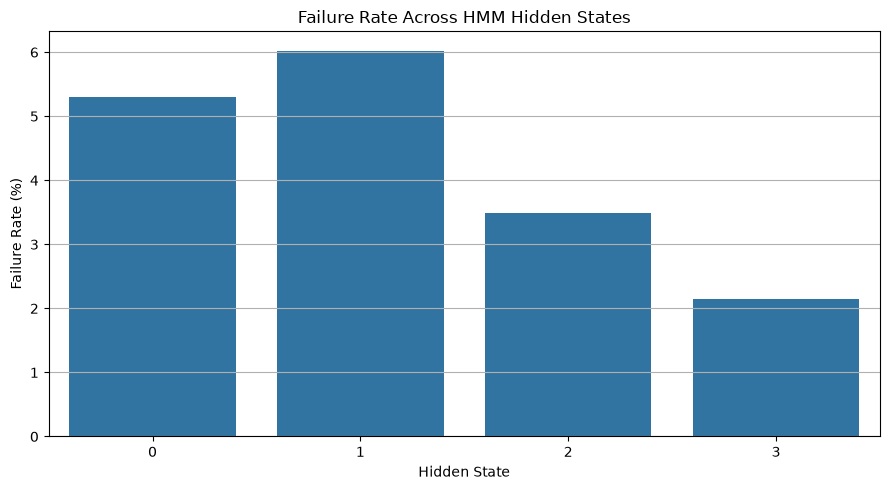

In [9]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=state_analysis.index,
    y=state_analysis["failure_rate"]
)

plt.xlabel("Hidden State")
plt.ylabel("Failure Rate (%)")
plt.title("Failure Rate Across HMM Hidden States")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

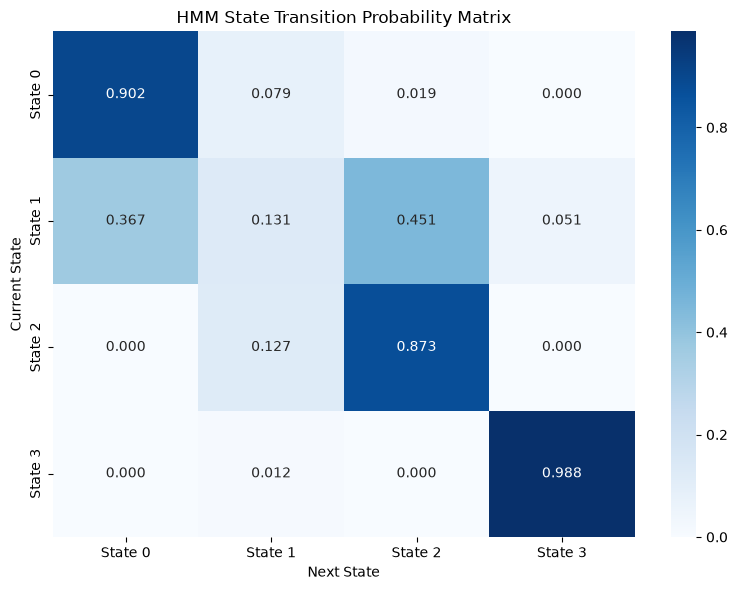

,State 0,State 1,State 2,State 3
State 0,0.902,0.079,0.019,0.000
State 1,0.367,0.131,0.451,0.051
State 2,0.000,0.127,0.873,0.000
State 3,0.000,0.012,0.000,0.988


In [10]:
transition_matrix = pd.DataFrame(
    hmm_model.transmat_,
    index=[f"State {i}" for i in range(4)],
    columns=[f"State {i}" for i in range(4)]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    transition_matrix,
    annot=True,
    cmap="Blues",
    fmt=".3f"
)

plt.xlabel("Next State")
plt.ylabel("Current State")
plt.title("HMM State Transition Probability Matrix")

plt.tight_layout()
plt.show()

display(transition_matrix.round(3))

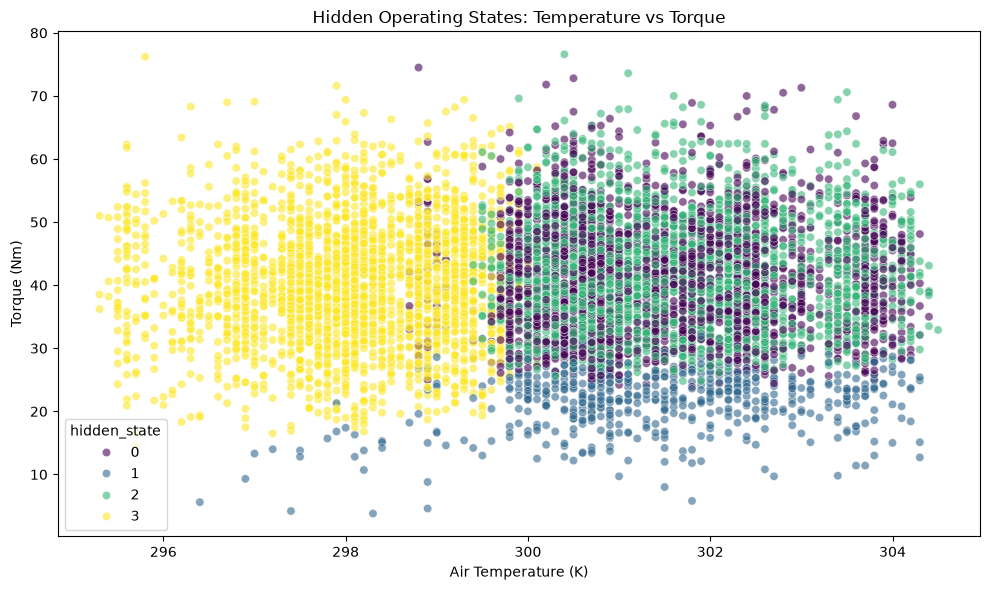

In [11]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train_results,
    x="air_temperature",
    y="torque",
    hue="hidden_state",
    palette="viridis",
    alpha=0.6
)

plt.title("Hidden Operating States: Temperature vs Torque")
plt.xlabel("Air Temperature (K)")
plt.ylabel("Torque (Nm)")
plt.tight_layout()
plt.show()

In [12]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)
os.makedirs("../results/predictions", exist_ok=True)

hmm_pipeline = {
    "scaler": scaler,
    "hmm_model": hmm_model,
    "sensor_features": sensor_features,
    "n_components": 4
}

joblib.dump(
    hmm_pipeline,
    "../models/hmm_pipeline.joblib"
)

print("HMM pipeline saved successfully.")

HMM pipeline saved successfully.


In [13]:
state_analysis.to_csv(
    "../results/metrics/hmm_state_analysis.csv"
)

transition_matrix.to_csv(
    "../results/metrics/hmm_transition_matrix.csv"
)

test_results.to_csv(
    "../results/predictions/hmm_test_states.csv",
    index=False
)

print("HMM results saved successfully.")

HMM results saved successfully.
